Họ tên: Phan Công Trí - MSSV: 6451071080
Đã tạo ảnh mẫu 'dog.png' (Bạn có thể upload file dog.png từ Drive của thầy đè lên nếu muốn).


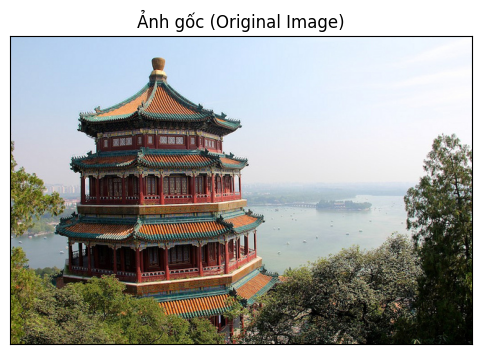

Kích thước ảnh gốc: Cao = 427, Rộng = 640, Kênh màu = 3
Kích thước mảng 2 chiều (rows * cols, 3): (273280, 3)


In [ ]:
# ==================== BÀI 6 (TRANG 26) ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

import os
import urllib.request
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Kiểm tra file dog.png (nếu chưa upload thì tải ảnh mẫu từ sklearn/github)
if not os.path.exists('dog.png'):
    from sklearn.datasets import load_sample_image
    sample_img = load_sample_image("china.jpg")
    Image.fromarray(sample_img).save('dog.png')
    print("Đã tạo ảnh mẫu 'dog.png' (Bạn có thể upload file dog.png từ Drive của thầy đè lên nếu muốn).")

# 1. Đọc vào file ảnh cần giảm kích thước và hiển thị ra màn hình
image = Image.open('dog.png').convert('RGB')
plt.figure(figsize=(6, 4))
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title("Ảnh gốc (Original Image)")
plt.show()

# 2. Chuyển ảnh đọc được thành mảng số và lấy thông tin chiều rộng, cao của ảnh
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print(f"Kích thước ảnh gốc: Cao = {rows}, Rộng = {cols}, Kênh màu = {imarr.shape[2]}")

# 3. Biến đổi các giá trị màu từ đoạn [0...255] về [0...1] và reshape từ 3D thành 2D
data = imarr / 255.0
data = data.reshape(rows * cols, 3)
print("Kích thước mảng 2 chiều (rows * cols, 3):", data.shape)

# 4. Chạy thuật toán gom cụm K-Means với số màu mong muốn là 32
kmeans = KMeans(n_clusters=32, max_iter=300, n_init=10, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

# 5. Khôi phục dạng mảng vừa thu được từ 2 chiều thành 3 chiều như ban đầu
img_recolored = new_colors.reshape(imarr.shape)

# 6. Biểu diễn hình kết quả và so sánh với ảnh gốc ban đầu
fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16)
plt.show()

# 7. Lưu hình kết quả xuống đĩa cứng và so sánh dung lượng file
img_recolored_uint8 = (img_recolored * 255).astype(np.uint8)
new_img = Image.fromarray(img_recolored_uint8)
new_img.save('compressed_img2.png')

orig_size = os.path.getsize('dog.png') / 1024
comp_size = os.path.getsize('compressed_img2.png') / 1024
print(f"Đã lưu 'compressed_img2.png' thành công!")
print(f"Dung lượng file gốc: {orig_size:.2f} KB | Dung lượng file sau khi giảm còn 32 màu: {comp_size:.2f} KB")